/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/upsetplot/data.py:303: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.fillna(False, inplace=True)
/Users/forough/VScodeProjects/VScode_serving/.venv/lib/python3.11/site-packages/upsetplot/plotting.py:795: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the 

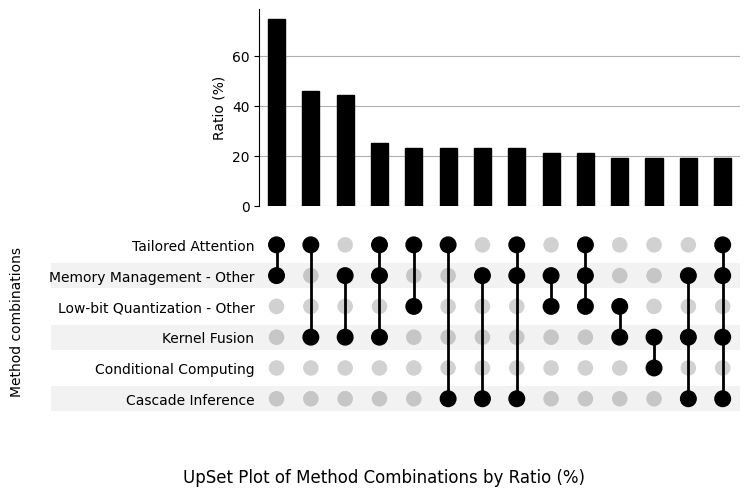

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from upsetplot import UpSet, from_memberships
# vllm
# df = pd.DataFrame({
#     "Method_combination": [
#         "Additional Parallel Computation methods, Memory Management - Other",
#         "Request Scheduling - Other, Memory Management - Other",
#         "Request Scheduling - Other, Additional Parallel Computation methods, Memory Management - Other",
#         "Request Scheduling - Other, Additional Parallel Computation methods",
#         "Additional Parallel Computation methods, Network Pruning",
#         "Low-bit Quantization - Other, Additional Parallel Computation methods",
#         "Network Pruning, Memory Management - Other",
#         "Additional Parallel Computation methods, Network Pruning, Memory Management - Other",
#         "Additional Parallel Computation methods, Memory Management - Other, Memory Management - Other",
#         "Request Scheduling - Other, Memory Management - Other",
#         "Request Scheduling - Other, Network Pruning",
#         "Request Scheduling - Other, Additional Parallel Computation methods, Network Pruning",
#         "Request Scheduling - Other, Additional Parallel Computation methods, Memory Management - Other",
#         "Low-bit Quantization - Other, Request Scheduling - Other",
#         "Low-bit Quantization - Other, Request Scheduling - Other, Additional Parallel Computation methods"
#     ],
#     "Ratio (%)": [15.10, 6.59, 6.42, 6.21, 6.04, 5.11, 4.56, 4.17, 2.42, 2.20, 2.20, 2.14, 2.14, 1.32, 1.32]
# })



#sglang
# df = pd.DataFrame({
#     "Method_combination": [
#         "Additional Parallel Computation methods, Memory Management - Other",
#         "Low-bit Quantization - Other, Additional Parallel Computation methods",
#         "Low-bit Quantization - Other, Memory Management - Other",
#         "Low-bit Quantization - Other, Additional Parallel Computation methods, Memory Management - Other",
#         "Request Scheduling - Other, Additional Parallel Computation methods",
#         "Request Scheduling - Other, Memory Management - Other",
#         "Request Scheduling - Other, Additional Parallel Computation methods, Memory Management - Other"
#     ],
#     "Ratio (%)": [
#         9.26,
#         5.56,
#         5.56,
#         5.56,
#         1.85,
#         1.85,
#         1.85
#     ]
# })



#tensorRT_llm
# df = pd.DataFrame({
#     "Method_combination": [
#         "Low-bit Quantization - Other, Memory Management - Other",
#         "Memory Management - Other, Request Scheduling - Other",
#         "Memory Management - Other, Additional Parallel Computation methods",
#         "Memory Management - Other, Request Scheduling - Other, Additional Parallel Computation methods",
#         "Request Scheduling - Other, Additional Parallel Computation methods",
#         "Memory Management - Other, Speculative Decoding, Network Pruning, Decoding Algorithm - other",
#         "Memory Management - Other, Request Scheduling - Other, Network Pruning, Decoding Algorithm - other",
#         "Memory Management - Other, Request Scheduling - Other, Speculative Decoding, Network Pruning, Decoding Algorithm - other",
#         "Memory Management - Other, Request Scheduling - Other, Speculative Decoding, Decoding Algorithm - other",
#         "Memory Management - Other, Request Scheduling - Other, Speculative Decoding, Network Pruning",
#         "Low-bit Quantization - Other, Memory Management - Other, Network Pruning, Decoding Algorithm - other",
#         "Memory Management - Other, Speculative Decoding, Network Pruning"
#     ],
#     "Ratio (%)": [
#         40.00,
#         40.00,
#         40.00,
#         40.00,
#         13.33,
#         13.33,
#         13.33,
#         13.33,
#         13.33,
#         13.33,
#         6.67,
#         6.67
#     ]
# })




#flashinfer 
df = pd.DataFrame({
    "Method_combination": [
        "Tailored Attention, Memory Management - Other",
        "Tailored Attention, Kernel Fusion",
        "Memory Management - Other, Kernel Fusion",
        "Tailored Attention, Memory Management - Other, Kernel Fusion",
        "Tailored Attention, Low-bit Quantization - Other",
        "Cascade Inference, Memory Management - Other",
        "Tailored Attention, Cascade Inference, Memory Management - Other",
        "Tailored Attention, Cascade Inference",
        "Tailored Attention, Memory Management - Other, Low-bit Quantization - Other",
        "Memory Management - Other, Low-bit Quantization - Other",
        "Kernel Fusion, Conditional Computing",
        "Cascade Inference, Memory Management - Other, Kernel Fusion",
        "Kernel Fusion, Low-bit Quantization - Other",
        "Tailored Attention, Cascade Inference, Memory Management - Other, Kernel Fusion"
    ],
    "Ratio (%)": [
        75.00,
        46.15,
        44.23,
        25.00,
        23.08,
        23.08,
        23.08,
        23.08,
        21.15,
        21.15,
        19.23,
        19.23,
        19.23,
        19.23
    ]
})


# Parse combinations
df["methods"] = df["Method_combination"].apply(
    lambda x: sorted(set(item.strip() for item in x.split(",") if item.strip()))
)

# Build upset data
upset_data = from_memberships(df["methods"], data=df["Ratio (%)"])
upset_data = upset_data.groupby(level=list(range(upset_data.index.nlevels))).sum()

# Plot
fig = plt.figure(figsize=(12, 6))

up = UpSet(
    upset_data,
    subset_size="sum",
    show_counts=False,
    sort_by="cardinality",
    sort_categories_by=None,
    totals_plot_elements=0
)

axes = up.plot(fig=fig)

# # Replace "Intersection size" with "Ratio (%)"
# axes["intersections"].set_ylabel("Ratio (%)")

# # Put "Methods combinations" under the dot matrix
# axes["matrix"].set_xlabel("Methods combinations")

# # Remove the old ylabel from the matrix axis if present
# axes["matrix"].set_ylabel("")
# Top bars
axes["intersections"].set_ylabel("Ratio (%)")

# Matrix labels
axes["matrix"].set_xlabel("")
axes["matrix"].set_ylabel("Method combinations", labelpad=18)
axes["matrix"].yaxis.set_label_position("left")
plt.suptitle("UpSet Plot of Method Combinations by Ratio (%)", y=0.02)
plt.tight_layout()
# plt.subplots_adjust(left=0.30)

plt.show()